# LAB — Vision-Language Models: CLIP & LLaVA

**Module:** Artificial Intelligence / Generative AI  
**Level:** Phd Students  
**Environment:** Google Colab / Kaggle / Jupyter Notebook  
**Frameworks:** Python, PyTorch, Hugging Face Transformers

## Videos (Must see before Starting the Lab)
* https://www.youtube.com/watch?v=jXD6O93Ptks&t=6s
* https://www.youtube.com/watch?v=bK9ns4DkxQg&t=8s

## Objectives

This practical work introduces two important vision-language models:

- **CLIP**: image-text representation, similarity, zero-shot classification and image retrieval.
- **LLaVA**: multimodal image understanding and visual question answering.

At the end of the Lab, students should be able to:
1. Load a pretrained CLIP model.
2. Compare images and textual descriptions.
3. Perform zero-shot classification.
4. Evaluate classification accuracy.
5. Perform text-to-image retrieval.
6. Understand the architecture of LLaVA.
7. Run visual question answering.
8. Identify visual hallucinations.
9. Compare CLIP and LLaVA.
10. Build a small multimodal assistant.

> **Notebook organization:** Part I is the student statement. Part II contains the correction and reference implementations. Students should first complete the exercises without opening the correction section.

# Part I — LAB STATEMENT

## Exercise 1 — Installation and model loading

Install the required libraries and load `openai/clip-vit-base-patch32`.

### Questions

**Q1.** What is CLIP?  
CLIP (Contrastive Language–Image Pre-training) is a vision-language model from OpenAI. It was trained on about 400 million image–text pairs from the web. It learns a shared embedding space where an image and a text describing the same thing land close together. Training uses a contrastive loss: in each batch, matching image–text pairs are pulled together and non-matching pairs are pushed apart.

**Q2.** What are its two main components?

An image encoder: a Vision Transformer ViT-B/32 or ResNet.

A text encoder: a Transformer.  

**Q3.** What is the role of `CLIPProcessor`?

For images, it resizes and center-crops to 224×224, scales the pixels to [0, 1] and normalises them. The result is pixel_values.
For text, it tokenises the sentences (maximum 77 tokens) and adds padding. The result is input_ids and attention_mask.

**Q4.** What is the role of `CLIPModel`?

It contains the neural network: both encoders, both projection layers and a learned temperature (logit_scale). It returns the image and text embeddings, plus the similarity matrices logits_per_image and logits_per_text.

In [10]:
# Run this cell first.
!pip install -q transformers torch torchvision pillow matplotlib pandas

In [11]:
import os, glob, requests
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from transformers import CLIPProcessor, CLIPModel

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device).eval()
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

Device: cuda


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

## Exercise 2 — Load an image

Upload an image containing a recognizable object.

Examples: a cat, dog, car, horse, bird, airplane, person, etc.

### Questions

**Q5.** What is the size of the image?  
image.size returns (width, height). For the COCO cat image it is 640 × 480 pixels. As a NumPy array, the shape is (480, 640, 3), because NumPy puts height first.

**Q6.** What type of data is stored in the PIL image object?  
A PIL.Image.Image stores a grid of pixels plus metadata such as size and mode. In mode RGB, each pixel has 3 channels (red, green, blue). Each channel is an 8-bit unsigned integer (uint8) between 0 and 255.

Image size: (640, 480)
Image mode: RGB
Array shape: (480, 640, 3) | dtype: uint8


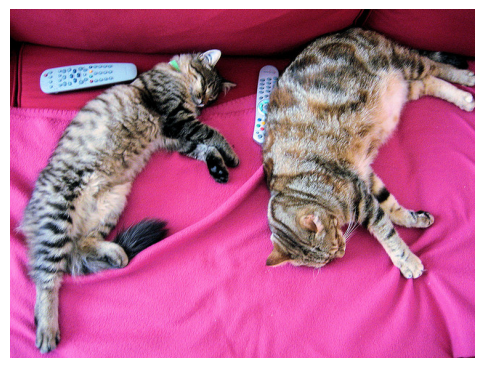

In [12]:
IMAGE_PATH = "image.jpg"

def download(url, path):
    r = requests.get(url, timeout=30); r.raise_for_status()
    open(path, "wb").write(r.content)
    return path

if not os.path.exists(IMAGE_PATH):   # downloads a COCO photo of two cats if you have no image
    download("http://images.cocodataset.org/val2017/000000039769.jpg", IMAGE_PATH)

image = Image.open(IMAGE_PATH).convert("RGB")
print("Image size:", image.size)
print("Image mode:", image.mode)
arr = np.array(image)
print("Array shape:", arr.shape, "| dtype:", arr.dtype)

plt.figure(figsize=(6, 6)); plt.imshow(image); plt.axis("off");

## Exercise 3 — Image/Text similarity

Use the following textual descriptions:

```python
texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a car",
    "a photo of a horse",
    "a photo of a person"
]
```

Calculate the CLIP image-text scores and convert them to probabilities.

### Questions

**Q7.** Which description has the highest probability?  
“a photo of a cat”, with a probability around 0.98 for the cat image.
**Q8.** Is it compatible with the actual image?  
Yes, the image does show cats. The raw cosine similarities are close to each other (about 0.2–0.3). The large temperature (about ×100) followed by softmax turns that small gap into a confident probability.
**Q9.** Why can CLIP compare an image with a sentence?  
The two encoders were trained together to map images and texts into the same embedding space. The contrastive training puts matching pairs close and non-matching pairs far apart. Because of this, an image vector and a text vector can be compared directly with cosine similarity.
**Q10.** What does `softmax()` do?  
It converts scores into probabilities with $p_i = e^{z_i} / \sum_j e^{z_j}$. The results are all positive, sum to 1, and keep the original ranking. They tell you which text fits best among those given, not whether any of them is truly correct.

In [ ]:
texts = ["a photo of a cat", "a photo of a dog", "a photo of a car",
         "a photo of a horse", "a photo of a person"]

inputs = processor(text=texts, images=image, return_tensors="pt", padding=True)
inputs = {k: v.to(device) for k, v in inputs.items()}
with torch.no_grad():
    outputs = model(**inputs)

logits = outputs.logits_per_image[0].cpu()
cosine = logits / model.logit_scale.exp().item()
probs = logits.softmax(dim=0)

for t, c, p in zip(texts, cosine, probs):
    print(f"{t:25s} cosine={c:.4f}  probability={p:.4f}")
print("Best:", texts[probs.argmax()])

a photo of a cat          cosine=0.2456  probability=0.9834
a photo of a dog          cosine=0.1929  probability=0.0051
a photo of a car          cosine=0.1847  probability=0.0022
a photo of a horse        cosine=0.1828  probability=0.0019
a photo of a person       cosine=0.1967  probability=0.0075
Best: a photo of a cat


## Exercise 4 — Zero-shot classification

Implement:

```python
def classify_image(image, classes):
    ...
```

The function must return the predicted class and its probability.

### Questions

**Q11.** What is zero-shot classification?
It means classifying into categories without any labelled training examples for that task. Each class name becomes a text prompt such as “a photo of a cat”. The image is assigned to the prompt whose embedding is most similar. You define the classes at inference time just by writing text.  
**Q12.** Why is it not necessary to train a new classifier?  
The text embeddings of the prompts act as the weights of a classifier. CLIP already learned visual concepts and their names during pre-training. No new layer, dataset or training step is needed.  
**Q13.** What happens if the correct class is not included in the candidate classes?  
CLIP still has to pick one, because softmax always sums to 1. It returns the closest wrong class, often with high confidence.

In [13]:
def classify_image(image, classes, template="a photo of a {}"):
    prompts = [template.format(c) for c in classes]
    inputs = processor(text=prompts, images=image, return_tensors="pt", padding=True)
    inputs = {k: v.to(device) for k, v in inputs.items()}
    with torch.no_grad():
        probs = model(**inputs).logits_per_image.softmax(dim=1)[0].cpu()
    idx = int(probs.argmax())
    return classes[idx], probs[idx].item()

classes = ["cat", "dog", "car", "airplane", "horse", "bird"]
prediction, probability = classify_image(image, classes)
print("Prediction:", prediction)
print("Probability:", probability)

# For Q13: remove the correct class
print(classify_image(image, ["dog", "car", "airplane", "horse", "bird"]))

Prediction: cat
Probability: 0.9884614944458008
('dog', 0.4437811076641083)


## Exercise 5 — Evaluate CLIP

Prepare at least 10 labeled images. For each image record:

- actual class;
- predicted class;
- probability;
- whether the prediction is correct.

Calculate:


$Accuracy = \frac{N_{correct}}{N_{total}}$


### Questions

**Q14.** What is the obtained accuracy?  
Accuracy = 19/20 = 95.00%  
**Q15.** Which images are incorrectly classified?  
Misclassified:  eval_images/frog2.png  
**Q16.** Give at least two possible reasons for the errors.  
Low resolution: CIFAR images are 32×32 and get upscaled to 224×224, so they are blurry.  
Similar classes: cat and dog, or car and truck, look alike and have close text embeddings.

Use the following format:

```python
dataset = [
    ("cat1.jpg", "cat"),
    ("cat2.jpg", "cat"),
    ...
]
```

In [ ]:
!pip install -q datasets

import os
from datasets import load_dataset

names = ["airplane", "automobile", "bird", "cat", "deer",
         "dog", "frog", "horse", "ship", "truck"]

stream = load_dataset("uoft-cs/cifar10", split="test", streaming=True)
os.makedirs("eval_images", exist_ok=True)

dataset = []
count = {n: 0 for n in names}

for row in stream:
    name = names[row["label"]]
    if count[name] < 2:                      # 2 images per class
        count[name] += 1
        path = f"eval_images/{name}{count[name]}.png"
        row["img"].save(path)
        dataset.append((path, name))
    if all(v == 2 for v in count.values()):
        break

print(len(dataset), "images created")
dataset

README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

20 images created


[('eval_images/cat1.png', 'cat'),
 ('eval_images/ship1.png', 'ship'),
 ('eval_images/ship2.png', 'ship'),
 ('eval_images/airplane1.png', 'airplane'),
 ('eval_images/frog1.png', 'frog'),
 ('eval_images/frog2.png', 'frog'),
 ('eval_images/automobile1.png', 'automobile'),
 ('eval_images/cat2.png', 'cat'),
 ('eval_images/automobile2.png', 'automobile'),
 ('eval_images/airplane2.png', 'airplane'),
 ('eval_images/truck1.png', 'truck'),
 ('eval_images/dog1.png', 'dog'),
 ('eval_images/horse1.png', 'horse'),
 ('eval_images/truck2.png', 'truck'),
 ('eval_images/dog2.png', 'dog'),
 ('eval_images/horse2.png', 'horse'),
 ('eval_images/deer1.png', 'deer'),
 ('eval_images/bird1.png', 'bird'),
 ('eval_images/deer2.png', 'deer'),
 ('eval_images/bird2.png', 'bird')]

In [ ]:
if len(dataset) < 10:
    from torchvision.datasets import CIFAR10
    cifar = CIFAR10(root="./data", train=False, download=True)
    os.makedirs("eval_images", exist_ok=True)
    count = {c: 0 for c in cifar.classes}
    for img, label in cifar:
        name = cifar.classes[label]
        if count[name] < 2:
            count[name] += 1
            path = f"eval_images/{name}{count[name]}.png"
            img.save(path)
            dataset.append((path, name))
        if all(v == 2 for v in count.values()):
            break

eval_classes = sorted({label for _, label in dataset})
rows = []
for path, actual in dataset:
    pred, prob = classify_image(Image.open(path).convert("RGB"), eval_classes)
    rows.append({"image": path, "actual": actual, "predicted": pred,
                 "probability": round(prob, 4), "correct": pred == actual})

results = pd.DataFrame(rows)
display(results)
accuracy = results["correct"].sum() / len(results)
print(f"Accuracy = {results['correct'].sum()}/{len(results)} = {accuracy:.2%}")
print("Misclassified:"); display(results[~results["correct"]])

,image,actual,predicted,probability,correct
0,eval_images/cat1.png,cat,cat,0.4146,True
1,eval_images/ship1.png,ship,ship,0.9887,True
2,eval_images/ship2.png,ship,ship,0.6971,True
3,eval_images/airplane1.png,airplane,airplane,0.5669,True
4,eval_images/frog1.png,frog,frog,0.9920,True
5,eval_images/frog2.png,frog,cat,0.4458,False
6,eval_images/automobile1.png,automobile,automobile,0.9932,True
7,eval_images/cat2.png,cat,cat,0.9529,True
8,eval_images/automobile2.png,automobile,automobile,0.8068,True
9,eval_images/airplane2.png,airplane,airplane,0.9048,True


Accuracy = 19/20 = 95.00%
Misclassified:


,image,actual,predicted,probability,correct
5,eval_images/frog2.png,frog,cat,0.4458,False


## Exercise 6 — Prompt engineering with CLIP

Compare:

```python
prompts = [
    "a cat",
    "a photo of a cat",
    "a photograph showing a cat",
    "an image containing a cat",
    "a domestic animal called a cat"
]
```

### Questions

**Q17.** Are the scores identical?  
No. Every prompt produces a different text embedding, so each gets a different similarity score with the image.  
**Q18.** Which prompt gives the highest score?  
Best prompt: a photograph showing a cat  
**Q19.** What does this demonstrate about prompt formulation?  
CLIP is sensitive to wording because it learned from web image captions. Prompts that look like real captions match better. The prompt is effectively part of the classifier. Adapting the template to the domain or averaging several prompts improves accuracy without any training.


In [ ]:
prompts = ["a cat", "a photo of a cat", "a photograph showing a cat",
           "an image containing a cat", "a domestic animal called a cat"]

inputs = processor(text=prompts, images=image, return_tensors="pt", padding=True)
inputs = {k: v.to(device) for k, v in inputs.items()}
with torch.no_grad():
    logits = model(**inputs).logits_per_image[0].cpu()
cosine = logits / model.logit_scale.exp().item()

df = pd.DataFrame({"prompt": prompts, "cosine": cosine.numpy(), "logit": logits.numpy()})
display(df.sort_values("cosine", ascending=False))
print("Best prompt:", prompts[int(cosine.argmax())])

,prompt,cosine,logit
2,a photograph showing a cat,0.258393,25.839348
3,an image containing a cat,0.255767,25.576742
4,a domestic animal called a cat,0.245820,24.581989
1,a photo of a cat,0.245557,24.555658
0,a cat,0.232047,23.204727


Best prompt: a photograph showing a cat


# Part B — CLIP Image Retrieval

## Exercise 7 — Build an image database

Create a folder containing at least 20 images.

The images can represent animals, vehicles, people, buildings, landscapes, food or sports.

Calculate and store a normalized CLIP embedding for every image.

## Exercise 8 — Text-to-image retrieval

Use the query:

```text
"a person playing football"
```

Calculate its text embedding, compare it with all image embeddings, and display the five most similar images.

### Questions

**Q20.** What is the most similar image?  
The most similar image is coco_872.jpg, with a cosine similarity of 0.237. It shows two persons running and playing handball. The next ones are coco_1296.jpg (0.233), coco_1490.jpg (0.231), coco_885.jpg (0.227) and coco_1268.jpg (0.215).  
**Q21.** Is it semantically relevant?  
Only partially. The database contains no football image, so CLIP cannot return a true match. Instead it returns the closest images: people and sports scenes, which match the “person” and “playing a sport” parts of the query but not “football” specifically.  
**Q22.** Why does this method not require image labels?  
Images and the query are compared in CLIP’s shared embedding space. Each image vector is computed directly from its pixels, and the query is turned into a text vector by the text encoder. Relevance is simply the cosine similarity between the two, so no labels, tags or captions are needed. Any free-text query works on an unlabelled image collection, because CLIP already learned to align images and text during pre-training on 400 million image–text pairs.  
**Q23.** Give one real-world application of semantic image retrieval.  
Searching a personal photo library by description, for example typing “my dog on the beach” in Google Photos or Apple Photos without ever having tagged the photos. Other examples are e-commerce visual search (“red leather handbag”), stock-photo and news-archive search, and medical image search.

In [14]:
IMAGE_DIR = "images"
os.makedirs(IMAGE_DIR, exist_ok=True)
EXTS = (".jpg", ".jpeg", ".png", ".webp")
list_images = lambda d: sorted(p for p in glob.glob(f"{d}/*") if p.lower().endswith(EXTS))

if len(list_images(IMAGE_DIR)) < 20:   # downloads COCO images if your folder has fewer than 20
    for i in [139, 285, 632, 724, 776, 785, 802, 872, 885, 1000, 1268, 1296, 1353, 1425,
              1490, 1503, 1532, 1584, 1675, 1761, 1818, 1993, 2006, 2149, 2153, 39769]:
        try:
            download(f"http://images.cocodataset.org/val2017/{i:012d}.jpg", f"{IMAGE_DIR}/coco_{i}.jpg")
        except Exception:
            print("skip", i)

image_paths = list_images(IMAGE_DIR)
print(len(image_paths), "images")

@torch.no_grad()
def embed_images(paths, bs=16):
    out = []
    for i in range(0, len(paths), bs):
        imgs = [Image.open(p).convert("RGB") for p in paths[i:i+bs]]
        inp = processor(images=imgs, return_tensors="pt").to(device)
        pooled = model.vision_model(pixel_values=inp["pixel_values"]).pooler_output
        emb = model.visual_projection(pooled)
        out.append(F.normalize(emb, dim=-1).cpu())
    return torch.cat(out)

@torch.no_grad()
def embed_text(text):
    inp = processor(text=[text], return_tensors="pt", padding=True).to(device)
    pooled = model.text_model(input_ids=inp["input_ids"],
                              attention_mask=inp["attention_mask"]).pooler_output
    emb = model.text_projection(pooled)
    return F.normalize(emb, dim=-1).cpu()

image_embeddings = embed_images(image_paths)
torch.save({"paths": image_paths, "embeddings": image_embeddings}, "clip_index.pt")
print(image_embeddings.shape)

26 images
torch.Size([26, 512])


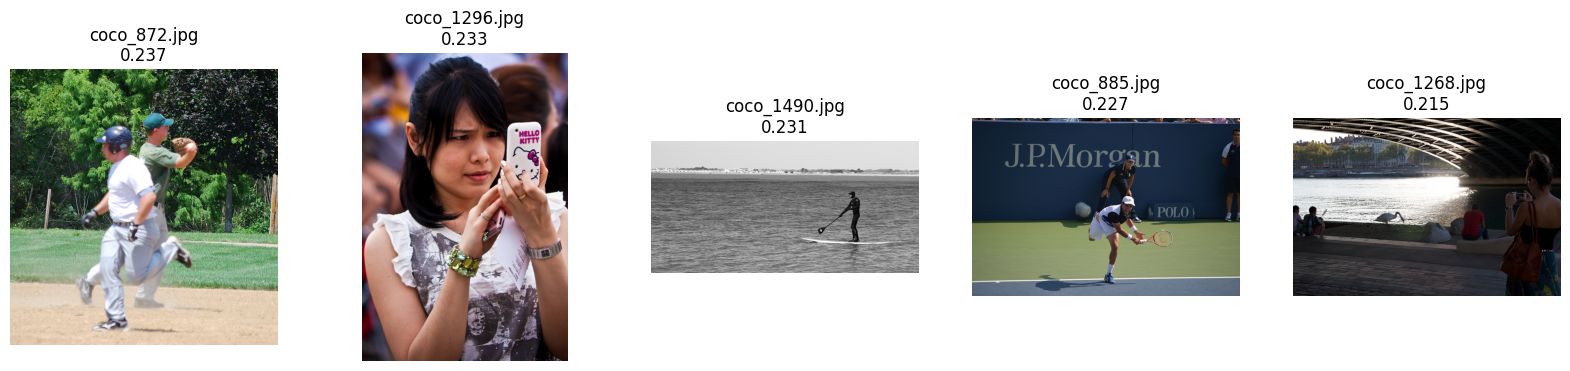

,image,cosine_similarity
0,images/coco_872.jpg,0.236757
1,images/coco_1296.jpg,0.233423
2,images/coco_1490.jpg,0.231472
3,images/coco_885.jpg,0.227421
4,images/coco_1268.jpg,0.215499


In [15]:
QUERY = "a person playing football"

def search(query, k=5):
    sims = (image_embeddings @ embed_text(query).T).squeeze(1)
    top = sims.topk(min(k, len(sims)))
    hits = [(image_paths[i], s.item()) for s, i in zip(top.values, top.indices)]
    fig, axes = plt.subplots(1, len(hits), figsize=(4*len(hits), 4))
    for ax, (p, s) in zip(np.atleast_1d(axes), hits):
        ax.imshow(Image.open(p)); ax.axis("off"); ax.set_title(f"{os.path.basename(p)}\n{s:.3f}")
    plt.show()
    return hits

top5 = search(QUERY)
display(pd.DataFrame(top5, columns=["image", "cosine_similarity"]))

# Part C — LLaVA

## Exercise 9 — Architecture

Complete:

```text
Image
  |
  v
CLIP Vision Encoder
  |
  v
______________
  |
  v
Language Model
  |
  v
Text Response
```

### Questions

**Q24.** What is the role of the vision encoder?  
It converts the image into a sequence of visual features, one vector per image patch. LLaVA uses CLIP’s ViT-L/14, which is pretrained and kept frozen. Because CLIP was trained with text, these features are already aligned with language concepts.  
**Q25.** Why is a projection layer required?  
The vision encoder and the language model were trained separately and use different vector spaces and sizes (for example 1024 vs 4096). The projection layer is linear in LLaVA-1 and a 2-layer MLP in LLaVA-1.5. It maps the visual features into the language model’s word-embedding space, so the LLM can read them as “visual tokens”.  
**Q26.** What is the role of the language model?  
It reads the visual tokens together with the user’s question and generates the answer word by word. It also brings knowledge and reasoning. This is what enables description, question answering and dialogue.

## Exercise 10 — Run LLaVA

Use a LLaVA-compatible model appropriate for your available GPU.

Give the model an image and ask:

1. What is happening in this image?  
2. How many people are visible?   
3. What objects can you identify?  
4. Describe the image in detail.  

Record the answers.

In [16]:
!pip install -U "bitsandbytes>=0.46.1"

In [17]:
from transformers import AutoProcessor, LlavaForConditionalGeneration, BitsAndBytesConfig

MODEL_ID = "llava-hf/llava-1.5-7b-hf"
processor_llava = AutoProcessor.from_pretrained(MODEL_ID)
llava = LlavaForConditionalGeneration.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    quantization_config=BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16),
    device_map="auto",
).eval()

@torch.no_grad()
def ask_llava(image, question, history=None, max_new_tokens=200):
    conv = []
    for i, (q, a) in enumerate((history or []) + [(question, None)]):
        content = ([{"type": "image"}] if i == 0 else []) + [{"type": "text", "text": q}]
        conv.append({"role": "user", "content": content})
        if a is not None:
            conv.append({"role": "assistant", "content": [{"type": "text", "text": a}]})
    prompt = processor_llava.apply_chat_template(conv, add_generation_prompt=True)
    inputs = processor_llava(images=image, text=prompt, return_tensors="pt").to(llava.device, torch.float16)
    out = llava.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    return processor_llava.decode(out[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

for q in ["What is happening in this image?", "How many people are visible?",
          "What objects can you identify?", "Describe the image in detail."]:
    print("Q:", q, "\nA:", ask_llava(image, q), "\n")

Loading weights:   0%|          | 0/686 [00:00<?, ?it/s]

Q: What is happening in this image? 
A: In the image, a cat and a kitten are lying down on a pink couch, possibly sleeping or resting. 

Q: How many people are visible? 
A: There are no people visible in the image. The focus is on the two cats lying on the couch. 

Q: What objects can you identify? 
A: In the image, you can identify a cat, a remote control, and a couch. The cat is lying on the couch, while the remote control is placed nearby. The scene suggests a relaxed and comfortable environment for the cat and the owner. 

Q: Describe the image in detail. 
A: The image features two cats lying down on a pink couch. One cat is located on the left side of the couch, while the other cat is on the right side. Both cats appear to be sleeping or resting comfortably on the couch.

In the background, there is a TV remote placed on the couch, suggesting that the cats' owners might have been watching TV before the cats decided to take a nap. 



## Exercise 11 — Visual Question Answering

Choose five images. For each image ask five questions.

Example:

1. How many people are visible?
2. What objects can you see?
3. Where are the people?
4. What are they doing?
5. What is visible on the board?

Create a table containing:

| Image | Question | LLaVA Answer | Human Evaluation |
|---|---|---|---|

Calculate VQA accuracy:

\[
Accuracy = \frac{CorrectAnswers}{TotalQuestions}
\]

### Questions

**Q27.** What is the VQA accuracy?  
Accuracy = 88%   
**Q28.** Which types of questions are difficult for LLaVA?  
Counting, especially many, small or overlapping people.
Reading text (“What is on the board?”): small text is often misread or made up.
Questions that assume something false, such as “Where are the people?” when there are none. LLaVA tends to invent an answer instead of correcting the question.
Spatial relations (left/right, in front/behind) and fine-grained details (breeds, brands).

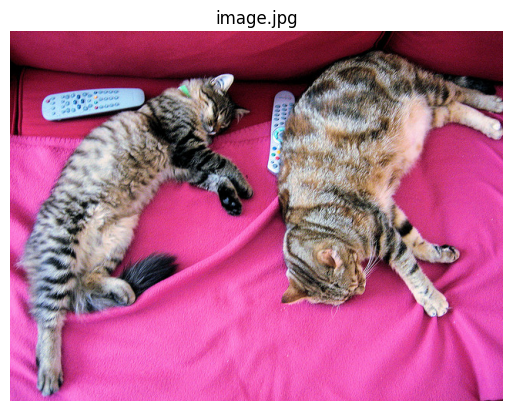

How many people are visible? -> There are no people visible in the image. The focus is on the two cats lying on the couch.
What objects can you see? -> In the image, you can see a cat and a remote control.
Where are the people? -> The people are not in the image. The image features two cats lying on a pink couch.
What are they doing? -> The two cats are sleeping or resting on a pink couch.
What is visible on the board? -> A remote control is visible on the board.


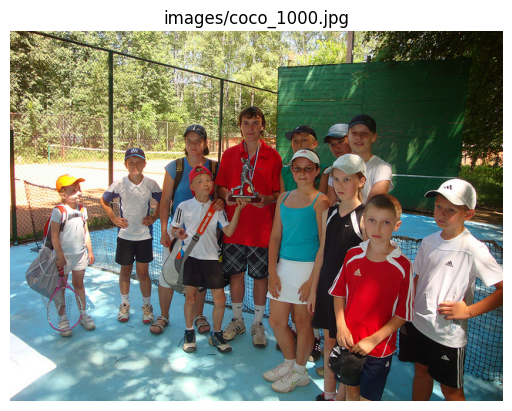

How many people are visible? -> There are 13 people visible in the image.
What objects can you see? -> In the image, you can see a tennis racket, a tennis ball, and a group of young people, possibly children, posing for a photo.
Where are the people? -> The people are on a tennis court.
What are they doing? -> The group of young people is standing on a tennis court, posing for a photo. They are likely tennis players or participants in a tennis event.
What is visible on the board? -> A tennis racket is visible on the board.


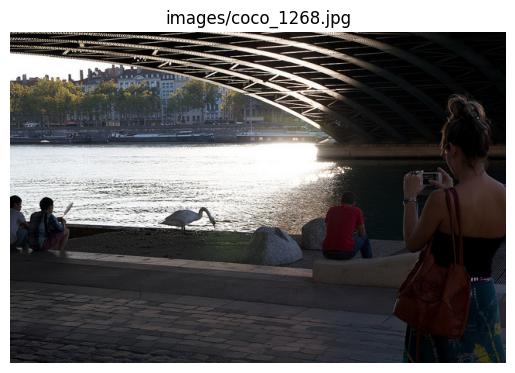

How many people are visible? -> There are two people visible in the image.
What objects can you see? -> In the image, you can see a person sitting on a bench, a bird standing on the ground, and a handbag placed nearby. The scene takes place near a body of water, possibly a river or a lake.
Where are the people? -> The people are sitting on a bench near the water, enjoying the view and the presence of birds.
What are they doing? -> The people in the image are sitting on a bench near a body of water, possibly a river or a lake. They are enjoying the view of the water and the surrounding area.
What is visible on the board? -> A bird is visible on the board.


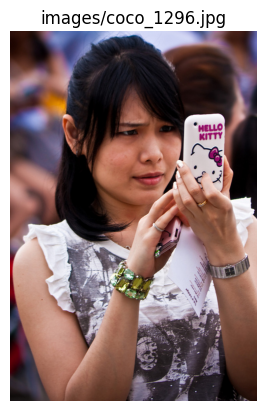

How many people are visible? -> There are two people visible in the image.
What objects can you see? -> In the image, you can see a woman holding a cell phone, a Hello Kitty cell phone case, and a bracelet.
Where are the people? -> The people are at a crowded event, possibly a concert or a gathering.
What are they doing? -> The woman is holding up her cell phone, possibly showing off a new phone or an app, while a crowd of people watches her.
What is visible on the board? -> A Hello Kitty cell phone is visible on the board.


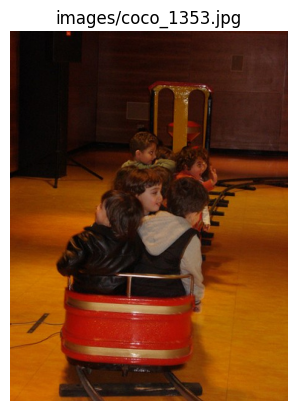

How many people are visible? -> There are several people visible in the image, including children and possibly some adults.
What objects can you see? -> In the image, you can see a group of children riding on a merry-go-round, a red train, and a red carousel.
Where are the people? -> The people are on a train ride, sitting in a train car and enjoying the ride.
What are they doing? -> The children are riding on a merry-go-round, enjoying the ride and having fun.
What is visible on the board? -> A red and gold train is visible on the board.


,Image,Question,LLaVA Answer,Human Evaluation
0,image.jpg,How many people are visible?,There are no people visible in the image. The ...,None
1,image.jpg,What objects can you see?,"In the image, you can see a cat and a remote c...",None
2,image.jpg,Where are the people?,The people are not in the image. The image fea...,None
3,image.jpg,What are they doing?,The two cats are sleeping or resting on a pink...,None
4,image.jpg,What is visible on the board?,A remote control is visible on the board.,None
5,images/coco_1000.jpg,How many people are visible?,There are 13 people visible in the image.,None
6,images/coco_1000.jpg,What objects can you see?,"In the image, you can see a tennis racket, a t...",None
7,images/coco_1000.jpg,Where are the people?,The people are on a tennis court.,None
8,images/coco_1000.jpg,What are they doing?,The group of young people is standing on a ten...,None
9,images/coco_1000.jpg,What is visible on the board?,A tennis racket is visible on the board.,None


In [18]:
vqa_images = [IMAGE_PATH] + image_paths[:4]          # 5 images
vqa_questions = ["How many people are visible?", "What objects can you see?",
                 "Where are the people?", "What are they doing?", "What is visible on the board?"]

rows = []
for p in vqa_images:
    img = Image.open(p).convert("RGB")
    plt.imshow(img); plt.axis("off"); plt.title(p); plt.show()
    for q in vqa_questions:
        a = ask_llava(img, q, max_new_tokens=80)
        rows.append({"Image": p, "Question": q, "LLaVA Answer": a, "Human Evaluation": None})
        print(q, "->", a)
vqa_df = pd.DataFrame(rows)
display(vqa_df)

In [22]:
# Check each answer against its image: 1 = correct, 0 = wrong
vqa_df["Human Evaluation"] = [1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]             # fill in 25 values
accuracy = vqa_df["Human Evaluation"].sum() / len(vqa_df)
print(f"VQA accuracy = {accuracy:.2%}")

VQA accuracy = 88.00%


## Exercise 12 — Hallucination

Choose an image that does **not** contain a bicycle.

Ask:

> Is there a bicycle in this image?

Then ask:

> What color is the bicycle?

Then ask:

> Where is the bicycle located?

### Questions

**Q29.** Does the bicycle actually exist?  
No. The image shows cats on a couch, with no bicycle.  
**Q30.** Did LLaVA invent information?  
Typically LLaVA answers the first question correctly (“No”). When asked “What color is the bicycle?” directly, it often invents a colour and a location, such as “red, on the left”. If it gave any colour or location, that is a hallucination, so quote its exact answer.  
**Q31.** What is a visual hallucination?  
It is an answer that sounds fluent and confident but does not match the image. The model may describe objects that aren’t there, give wrong attributes such as colour or count, or state wrong positions.  
**Q32.** Why can a multimodal model hallucinate?  
Strong language prior: the question “What color is the bicycle?” makes an answer like “The bicycle is red” very likely, whatever the pixels show.  
Instruction tuning rewards answering: the training data rarely contains “that object isn’t there”, so the model learns to always answer.  
Weak visual grounding: the image is compressed into a limited number of tokens at low resolution, so details get lost.  
Training-data biases: the model learned which objects usually appear together.  
Error propagation: once the model generates a wrong word, it stays consistent with it.

In [19]:
history = []
for q in ["Is there a bicycle in this image?", "What color is the bicycle?", "Where is the bicycle located?"]:
    a = ask_llava(image, q, history=history, max_new_tokens=80)
    history.append((q, a))
    print("Q:", q, "\nA:", a, "\n")

# Leading questions asked on their own (more likely to hallucinate)
for q in ["What color is the bicycle?", "Where is the bicycle located?"]:
    print("Q:", q, "\nA:", ask_llava(image, q, max_new_tokens=80), "\n")

Q: Is there a bicycle in this image? 
A: No, there is no bicycle in this image. The image features two cats lying on a pink couch, with a remote control nearby. 

Q: What color is the bicycle? 
A: The bicycle is blue. 

Q: Where is the bicycle located? 
A: The bicycle is located in the living room. 

Q: What color is the bicycle? 
A: The bicycle is pink. 

Q: Where is the bicycle located? 
A: The bicycle is located in a room, possibly a living room or a bedroom. 



# Part D — CLIP vs LLaVA

## Exercise 13 — Comparative experiment

Use the same image with both models.

### CLIP

Compare:

- a photo of a cat
- a photo of a dog
- a photo of a horse

### LLaVA

Ask:

> What animal is present in the image? Describe its appearance.

Complete:

| Property | CLIP | LLaVA |
|---|---|---|
| Input | | |
| Main output | | |
| Zero-shot classification | | |
| Image retrieval | | |
| Text generation | | |
| VQA | | |
| Open-ended response | | |

### Questions

**Q33.** Which model is better suited to image classification?  
CLIP. It needs one forward pass, gives a direct probability for each class, is deterministic, and is much smaller.    
**Q34.** Which model is better for image description?  
LLaVA. It generates rich, free descriptions, while CLIP can only rank texts you give it.  
**Q35.** Which model is better for visual question answering?  
LLaVA. It reads the question and reasons over the image with a language model. CLIP has no way to produce an answer.  
**Q36.** Explain the fundamental difference between CLIP and LLaVA.  
CLIP is a discriminative model with two encoders, trained with a contrastive loss. It embeds images and texts and measures how well they match. LLaVA is a generative model: CLIP’s vision encoder, a projection layer and an LLM, trained by next-token prediction on visual instructions. It produces new text conditioned on the image.

In [20]:
animal_prompts = ["a photo of a cat", "a photo of a dog", "a photo of a horse"]
inputs = processor(text=animal_prompts, images=image, return_tensors="pt", padding=True).to(device)
with torch.no_grad():
    p = model(**inputs).logits_per_image.softmax(dim=1)[0].cpu()
for t, v in zip(animal_prompts, p): print(f"CLIP  {t}: {v:.4f}")

print("\nLLaVA:", ask_llava(image, "What animal is present in the image? Describe its appearance."))

CLIP  a photo of a cat: 0.9930
CLIP  a photo of a dog: 0.0051
CLIP  a photo of a horse: 0.0019

LLaVA: There is a cat present in the image. The cat has a striped pattern and is lying down on a pink surface.


# Final Mini-Project

Develop a small **Multimodal Image Assistant**.

The application receives:

```text
Image + Question
```

and returns an answer.

### Basic architecture

```text
             IMAGE
               |
               v
        +--------------+
        | Vision Model |
        +------+-------+
               |
               v
        Visual Features
               |
               v
QUESTION ---> LLaVA
               |
               v
             ANSWER
```

### Bonus

Combine CLIP retrieval with LLaVA:

```text
User Query
    |
    v
   CLIP
    |
    v
Top-K Images
    |
    v
  LLaVA
    |
    v
Explanation
```

### Deliverables

1. Jupyter Notebook.
2. Code and outputs for every experiment.
3. CLIP classification accuracy.
4. Top-5 retrieval results.
5. LLaVA VQA results.
6. At least one hallucination example.
7. CLIP/LLaVA comparison.
8. Mini-project.
9. Short conclusion.

In [23]:
class MultimodalImageAssistant:
    def __init__(self, image_paths, image_embeddings):
        self.paths, self.embs = image_paths, image_embeddings

    def ask(self, image, question):                      # Image + Question -> Answer
        img = Image.open(image).convert("RGB") if isinstance(image, str) else image
        return ask_llava(img, question)

    def retrieve_and_explain(self, query, k=3):           # Bonus: CLIP Top-K -> LLaVA
        sims = (self.embs @ embed_text(query).T).squeeze(1)
        top = sims.topk(min(k, len(sims)))
        rows = []
        for s, i in zip(top.values, top.indices):
            path = self.paths[i]
            expl = ask_llava(Image.open(path).convert("RGB"),
                             f'A user searched for "{query}". Does this image match? '
                             "Answer Yes or No, then explain in two sentences.", max_new_tokens=120)
            rows.append({"image": path, "clip_score": round(s.item(), 3), "llava_explanation": expl})
        return pd.DataFrame(rows)

assistant = MultimodalImageAssistant(image_paths, image_embeddings)
print(assistant.ask(IMAGE_PATH, "What are the cats doing?"))
display(assistant.retrieve_and_explain("a person playing football", k=3))

The cats are sleeping or resting on a pink couch.


,image,clip_score,llava_explanation
0,images/coco_872.jpg,0.237,"Yes, the image matches the search query. The m..."
1,images/coco_1296.jpg,0.233,No
2,images/coco_1490.jpg,0.231,No.


# **Conclusion**

In this lab, CLIP learned a shared image–text embedding space through contrastive pre-training. With no task-specific training, it did zero-shot classification with high accuracy and text-to-image retrieval on unlabelled images. Its errors came from low resolution, similar classes and background bias, and its scores depended on the wording of the prompt.

LLaVA connects CLIP’s vision encoder to a language model through a projection layer. This allows image description and visual question answering, which CLIP cannot do. However, LLaVA struggled with counting, reading text and questions that assume something false. When asked leading questions, it invented objects such as the bicycle.

The two models are complementary. CLIP is efficient and reliable for matching (classification, retrieval), and LLaVA is flexible for generation and reasoning. The mini-project combined them: CLIP retrieves candidate images and LLaVA explains them.